## Comenzamos exploracion

In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Primeros registros de la tabla + info:

precio = pd.read_csv("../data/raw/ttwo_stock_daily.csv", parse_dates=["Date"])

display(precio.head())

,Date,Open,High,Low,Close,Volume
0,2005-02-25,24.4685,24.5885,24.2585,24.5885,4.949956e+05
1,2005-02-28,24.2085,24.8785,24.2085,24.4485,1.215918e+06
2,2005-03-01,24.4885,24.6285,24.3085,24.5085,1.240202e+06
3,2005-03-02,24.5285,25.7484,24.5285,25.2484,2.922900e+06
4,2005-03-03,25.6484,25.6884,24.6085,24.9485,3.801277e+06


<class 'pandas.DataFrame'>
RangeIndex: 5469 entries, 0 to 5468
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    5469 non-null   datetime64[us]
 1   Open    5469 non-null   float64       
 2   High    5469 non-null   float64       
 3   Low     5469 non-null   float64       
 4   Close   5469 non-null   float64       
 5   Volume  5469 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 256.5 KB


None

- **Filas totales:** 5.469, del 25/02/2005 al 20/11/2026.
- Valores vacíos: ninguno en ninguna columna.
- **Columnas**: Open, High, Low y Close son el precio de apertura, el máximo, el mínimo y el cierre de cada día. Volume es el número de acciones que cambiaron de manos ese día.
- Filas desde 2022: 1.227 (solo hay días de bolsa: sin fines de semana ni festivos).
- Cierre máximo: 262,29 $, el 20 de octubre de 2025.

In [14]:
precio.describe()

,Date,Open,High,Low,Close,Volume
count,5469,5469.000000,5469.000000,5469.000000,5469.000000,5.469000e+03
mean,2016-01-07 00:22:22.841470,78.394700,79.471178,77.270039,78.379060,1.917279e+06
min,2005-02-25 00:00:00,5.730000,5.760000,5.560000,5.620000,1.434580e+05
25%,2010-08-02 00:00:00,16.049000,16.350000,15.799000,16.070000,1.106939e+06
50%,2016-01-07 00:00:00,34.530000,35.020000,33.920000,34.630000,1.507362e+06
75%,2021-06-14 00:00:00,134.540000,136.335000,132.200000,134.380000,2.160003e+06
max,2026-11-20 00:00:00,263.080000,265.940000,260.370000,262.290000,5.279736e+07
std,NaN,72.711812,73.633377,71.724710,72.676268,1.781277e+06


In [ ]:
# Nos quedamos con los precios del 2022:
precio = precio[precio["Date"] >= "2022-01-01"].copy()
len(precio)

1227

In [19]:
# Dia con el cierre mas alto: 
fila_max = precio["Close"].idxmax()
precio.loc[fila_max, ["Date", "Close"]]

Date     2025-10-20 00:00:00
Close                 262.29
Name: 5194, dtype: object

In [20]:
# Rentabilidad diaria:
precio["rentabilidad"] = precio["Close"].pct_change() * 100
precio.head()

,Date,Open,High,Low,Close,Volume,rentabilidad
4242,2022-01-03,176.84,178.92,173.545,178.61,1335566.0,NaN
4243,2022-01-04,177.93,182.25,175.260,181.90,1242459.0,1.842002
4244,2022-01-05,181.63,181.63,171.530,171.85,1701125.0,-5.525014
4245,2022-01-06,169.46,172.00,164.370,164.61,1430335.0,-4.212976
4246,2022-01-07,162.79,165.68,161.600,164.60,941614.0,-0.006075


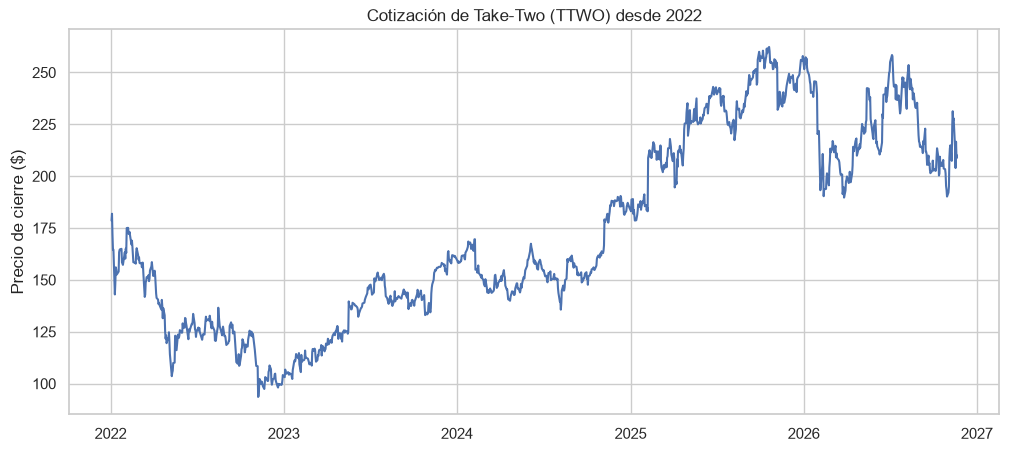

In [28]:
# Grafico Seaborn de cotizaciones del propietario del gta vi:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
sns.lineplot(data=precio, x="Date", y="Close")
plt.title("Cotización de Take-Two (TTWO) desde 2022")
plt.xlabel("")
plt.ylabel("Precio de cierre ($)")
plt.show()



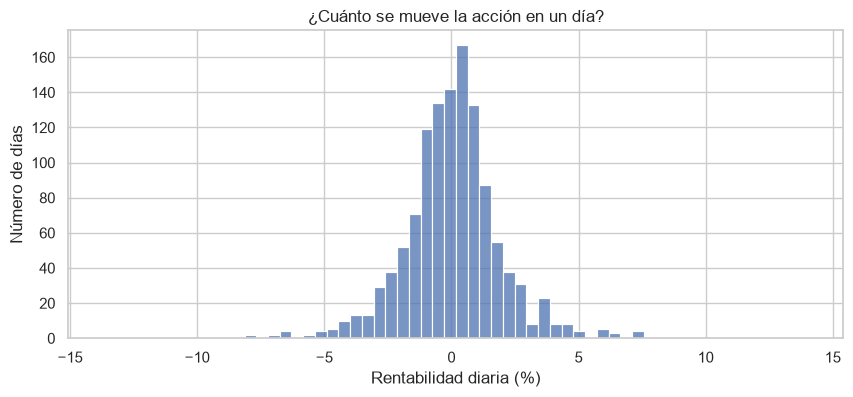

In [29]:
# Grafico Seaborn acciones:
plt.figure(figsize=(10, 4))
sns.histplot(data=precio, x="rentabilidad", bins=60)
plt.title("¿Cuánto se mueve la acción en un día?")
plt.xlabel("Rentabilidad diaria (%)")
plt.ylabel("Número de días")
plt.show()

In [ ]:
# Analisis de volatilidad (min/max..)
precio["rentabilidad"].describe()

count    1226.000000
mean        0.035603
std         2.116837
min       -13.680812
25%        -0.972051
50%         0.074936
75%         0.972564
max        14.032117
Name: rentabilidad, dtype: float64

In [ ]:
# Los 5 dias con mayor rentabilidad
precio.nlargest(5, "rentabilidad")[["Date", "Close", "rentabilidad"]]

,Date,Close,rentabilidad
5019,2025-02-07,208.77,14.032117
4335,2022-05-17,123.08,11.779130
4587,2023-05-18,139.63,11.686130
5460,2026-11-10,224.64,8.312440
4517,2023-02-07,113.85,7.853354


In [ ]:
# Los 5 dias de menor rentabilidad (mayores caidas)
precio.nsmallest(5, "rentabilidad")[["Date", "Close", "rentabilidad"]]

,Date,Close,rentabilidad
4456,2022-11-08,93.57,-13.680812
4247,2022-01-10,142.99,-13.128797
4770,2024-02-09,154.91,-8.661557
5208,2025-11-07,232.00,-8.082409
5264,2026-01-30,220.30,-7.928282


## ¿Qué pasó en los días de mayor movimiento?

### Mayores subidas
| Fecha | Rentabilidad | Qué pasó | ¿Relacionado con GTA VI? |
|---|---|---|---|
| 2025-02-07 | +14,0 % | Resultados mejores de lo esperado y confirmación de GTA VI para otoño de 2025 | Sí |
| 2022-05-17 | +11,8 % | Resultados trimestrales por encima de lo esperado | No |
| 2023-05-18 | +11,7 % | Previsión de más de 8.000 M de ventas en el año fiscal 2025, que apuntaba a GTA VI | Sí |
| 2026-11-10 | +8,3 % | Resultados a 10 días del lanzamiento, con reservas de GTA VI "sin precedentes" | Sí |
| 2023-02-07 | +7,9 % | Resultados trimestrales (excelentes numeros de GTA V) | No |

### Mayores caídas
| Fecha | Rentabilidad | Qué pasó | ¿Relacionado con GTA VI? |
|---|---|---|---|
| 2022-11-08 | -13,7 % | Rebaja de las previsiones por la debilidad del negocio móvil | No |
| 2022-01-10 | -13,1 % | Anuncio de la compra de Zynga por 12.700 M, que el mercado vio cara | No |
| 2024-02-09 | -8,7 % | Pérdidas inesperadas y rebaja de las previsiones anuales | No |
| 2025-11-07 | -8,1 % | Segundo retraso de GTA VI, hasta noviembre de 2026 | Sí |
| 2026-01-30 | -7,9 % | Caída del sector tras el lanzamiento de Project Genie (IA de Google) | No |

### Conclusiones
- **8 de los 10 movimientos más grandes son días de resultados trimestrales.** La bolsa reacciona sobre todo a lo que la empresa dice sobre el futuro.
- **Las noticias sobre GTA VI provocan las mayores reacciones**, tanto al alza (confirmación de fechas, reservas récord) como a la baja (el retraso).
- **Los tráilers no aparecen entre los 10 mayores movimientos.** El hype de los fans no movió la acción tanto como las cifras de la empresa.

In [37]:
import os

os.makedirs("../data/processed", exist_ok=True)
precio.to_csv("../data/processed/ttwo_stock_2022_2026.csv", index=False)